In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Assignment6_Data.xlsx to Assignment6_Data.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_excel('Assignment6_Data.xlsx')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (32, 11)


,Timestamp,What best describes your current role?,How familiar are you with AI/ML-based Intrusion Detection Systems?,Do you currently use or rely on AI-based IDS for network security or intrusion detection?,How frequently do you use AI-based IDS?,How would you rate your trust in AI-based IDS detection results?,Have you experienced false alarms (false positives) from an AI-based IDS?,What is the main reason you do not rely on AI-based IDS?,What do you consider the biggest challenge in AI-based intrusion detection?,Which factor is most important for a reliable AI-based IDS?,Would you consider adopting AI-based IDS in the future?
0,2026-11-20 23:29:15.442,Postgraduate Student,Very familiar,Yes,Ocassionally,Moderate,Sometimes,Lack of awareness,Lack of explainability or transparency,Ability to detect unseen attacks,Not sure
1,2026-11-20 23:32:29.716,Postgraduate Student,Very familiar,No,NaN,NaN,NaN,Not applicable / Not sure,Lack of explainability or transparency,High detection accuracy,Definitely yes
2,2026-11-20 23:39:15.000,Undergraduate Student,Very familiar,Yes,Daily,Very high,Never,—,High false-positive rate,Low false-positive rate,Definitely yes
3,2026-11-20 23:45:15.000,Postgraduate Student,Moderately familiar,Yes,Weekly,High,Sometimes,—,Difficulty detecting new or unknown attacks,Ability to detect unseen attacks,Probably yes
4,2026-11-20 23:52:15.000,Research Scholar,Very familiar,Yes,Occasionally,Moderate,Rarely,—,Poor generalisation across different network e...,Generalisation across different datasets or ne...,Not sure


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe(include='all')

Column Names:
['Timestamp', 'What best describes your current role?', 'How familiar are you with AI/ML-based Intrusion Detection Systems?', 'Do you currently use or rely on AI-based IDS for network security or intrusion detection?', 'How frequently do you use AI-based IDS?', 'How would you rate your trust in AI-based IDS detection results?', 'Have you experienced false alarms (false positives) from an AI-based IDS?', 'What is the main reason you do not rely on AI-based IDS?', 'What do you consider the biggest challenge in AI-based intrusion detection?', 'Which factor is most important for a reliable AI-based IDS?', 'Would you consider adopting AI-based IDS in the future?']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 11 columns):
 #   Column                                                                                     Non-Null Count  Dtype         
---  ------                                                       

,Timestamp,What best describes your current role?,How familiar are you with AI/ML-based Intrusion Detection Systems?,Do you currently use or rely on AI-based IDS for network security or intrusion detection?,How frequently do you use AI-based IDS?,How would you rate your trust in AI-based IDS detection results?,Have you experienced false alarms (false positives) from an AI-based IDS?,What is the main reason you do not rely on AI-based IDS?,What do you consider the biggest challenge in AI-based intrusion detection?,Which factor is most important for a reliable AI-based IDS?,Would you consider adopting AI-based IDS in the future?
count,32,32,32,32,31,31,31,32,32,32,32
unique,NaN,6,5,3,6,6,6,7,6,5,5
top,NaN,Postgraduate Student,Very familiar,Yes,—,—,—,—,Lack of explainability or transparency,Ability to detect unseen attacks,Not sure
freq,NaN,9,8,13,18,18,18,20,6,7,9
mean,2026-11-22 01:53:10.161187328,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,2026-11-20 08:29:15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2026-11-21 09:53:39.249999872,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2026-11-22 10:15:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2026-11-22 17:54:39.750000128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,2026-11-22 22:16:48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

# ==========================================
# ASSIGNMENT 6: DATA PREPARATION
# ==========================================

import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Create a working copy
data = df.copy()

# Expected structure: Timestamp + 10 survey questions
if data.shape[1] < 11:
    raise ValueError(
        "The dataset has fewer than 11 columns. "
        "Please check the Excel file and its column names."
    )

# Assign simple, consistent column names
data = data.iloc[:, :11].copy()

data.columns = [
    "Timestamp",
    "Role",
    "Familiarity",
    "Current_Use",
    "Usage_Frequency",
    "Trust",
    "False_Positives",
    "Non_Use_Reason",
    "Biggest_Challenge",
    "Reliability_Factor",
    "Future_Adoption"
]

# Remove unnecessary spaces from text responses
for column in data.columns:
    if data[column].dtype == "object":
        data[column] = data[column].apply(
            lambda x: " ".join(x.split()) if isinstance(x, str) else x
        )

# Convert timestamp
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"], errors="coerce"
)

# Remove exact duplicate records
duplicate_count = data.duplicated().sum()
data = data.drop_duplicates().copy()

print("DATA PREPARATION COMPLETED")
print("--------------------------------")
print("Number of responses:", len(data))
print("Duplicate records removed:", duplicate_count)
print("Number of columns:", len(data.columns))

print("\nMissing values:")
print(data.isnull().sum())

print("\nDataset preview:")
display(data.head())


DATA PREPARATION COMPLETED
--------------------------------
Number of responses: 32
Duplicate records removed: 0
Number of columns: 11

Missing values:
Timestamp             0
Role                  0
Familiarity           0
Current_Use           0
Usage_Frequency       1
Trust                 1
False_Positives       1
Non_Use_Reason        0
Biggest_Challenge     0
Reliability_Factor    0
Future_Adoption       0
dtype: int64

Dataset preview:


,Timestamp,Role,Familiarity,Current_Use,Usage_Frequency,Trust,False_Positives,Non_Use_Reason,Biggest_Challenge,Reliability_Factor,Future_Adoption
0,2026-11-20 23:29:15.442,Postgraduate Student,Very familiar,Yes,Ocassionally,Moderate,Sometimes,Lack of awareness,Lack of explainability or transparency,Ability to detect unseen attacks,Not sure
1,2026-11-20 23:32:29.716,Postgraduate Student,Very familiar,No,NaN,NaN,NaN,Not applicable / Not sure,Lack of explainability or transparency,High detection accuracy,Definitely yes
2,2026-11-20 23:39:15.000,Undergraduate Student,Very familiar,Yes,Daily,Very high,Never,—,High false-positive rate,Low false-positive rate,Definitely yes
3,2026-11-20 23:45:15.000,Postgraduate Student,Moderately familiar,Yes,Weekly,High,Sometimes,—,Difficulty detecting new or unknown attacks,Ability to detect unseen attacks,Probably yes
4,2026-11-20 23:52:15.000,Research Scholar,Very familiar,Yes,Occasionally,Moderate,Rarely,—,Poor generalisation across different network e...,Generalisation across different datasets or ne...,Not sure


In [ ]:

# ==========================================
# DESCRIPTIVE STATISTICAL ANALYSIS
# ==========================================

survey_questions = [
    "Role",
    "Familiarity",
    "Current_Use",
    "Usage_Frequency",
    "Trust",
    "False_Positives",
    "Non_Use_Reason",
    "Biggest_Challenge",
    "Reliability_Factor",
    "Future_Adoption"
]

# Frequency and percentage tables
frequency_tables = {}

for column in survey_questions:
    print("\n--------------------------------")
    print("Variable:", column)
    print("--------------------------------")

    frequency = data[column].value_counts(dropna=False)
    percentage = (
        data[column].value_counts(normalize=True, dropna=False) * 100
    )

    result = pd.DataFrame({
        "Frequency": frequency,
        "Percentage": percentage.round(2)
    })

    frequency_tables[column] = result
    display(result)

# Convert selected ordinal variables into numerical scores
ordinal_mappings = {
    "Familiarity": {
        "Not familiar at all": 1,
        "Heard of them but know very little": 2,
        "Slightly familiar": 3,
        "Moderately familiar": 4,
        "Very familiar": 5
    },
    "Trust": {
        "Very low": 1,
        "Low": 2,
        "Moderate": 3,
        "High": 4,
        "Very high": 5
    },
    "Future_Adoption": {
        "Definitely no": 1,
        "Probably no": 2,
        "Not sure": 3,
        "Probably yes": 4,
        "Definitely yes": 5
    }
}

ordinal_data = pd.DataFrame()

for column, mapping in ordinal_mappings.items():
    ordinal_data[column] = (
        data[column].astype("string").str.strip().map(mapping)
    )

print("\nORDINAL VARIABLE SUMMARY")
display(ordinal_data.describe().round(2))

# Mode for all survey questions
print("\nMODE OF SURVEY RESPONSES")
for column in survey_questions:
    modes = data[column].mode(dropna=True)
    if len(modes) > 0:
        print(column, ":", ", ".join(map(str, modes.tolist())))
    else:
        print(column, ": No available responses")



--------------------------------
Variable: Role
--------------------------------


,Frequency,Percentage
Role,,
Postgraduate Student,9,28.12
Undergraduate Student,6,18.75
IT Professional,6,18.75
Research Scholar,4,12.50
Cybersecurity Professional,4,12.50
Other,3,9.38



--------------------------------
Variable: Familiarity
--------------------------------


,Frequency,Percentage
Familiarity,,
Very familiar,8,25.00
Moderately familiar,8,25.00
Slightly familiar,7,21.88
Not familiar at all,5,15.62
Heard of them but know very little,4,12.50



--------------------------------
Variable: Current_Use
--------------------------------


,Frequency,Percentage
Current_Use,,
Yes,13,40.62
No,11,34.38
Not sure,8,25.00


... (13 outputs left out)

,Frequency,Percentage
Future_Adoption,,
Not sure,9,28.12
Definitely yes,8,25.00
Probably yes,7,21.88
Probably no,5,15.62
Definitely no,3,9.38



ORDINAL VARIABLE SUMMARY


,Familiarity,Trust,Future_Adoption
count,32.00,13.00,32.00
mean,3.31,3.15,3.38
std,1.40,1.21,1.29
min,1.00,1.00,1.00
25%,2.00,2.00,2.75
50%,3.50,3.00,3.00
75%,4.25,4.00,4.25
max,5.00,5.00,5.00



MODE OF SURVEY RESPONSES
Role : Postgraduate Student
Familiarity : Moderately familiar, Very familiar
Current_Use : Yes
Usage_Frequency : —
Trust : —
False_Positives : —
Non_Use_Reason : —
Biggest_Challenge : High false-positive rate, Lack of explainability or transparency, Poor generalisation across different network environments or datasets
Reliability_Factor : Ability to detect unseen attacks, Generalisation across different datasets or networks, High detection accuracy
Future_Adoption : Not sure


In [ ]:

# ==========================================
# INFERENTIAL STATISTICAL ANALYSIS
# ==========================================

def perform_association_test(table, title):

    print("\n====================================")
    print(title)
    print("====================================")

    display(table)

    # A valid 2x2 table is needed for these tests
    if table.shape != (2, 2):
        print("Test not performed: a complete 2x2 table is required.")
        return None

    if (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any():
        print("Test not performed: one category has no observations.")
        return None

    chi2, p_chi, dof, expected = stats.chi2_contingency(
        table, correction=False
    )

    print("\nExpected frequencies:")
    print(pd.DataFrame(
        expected,
        index=table.index,
        columns=table.columns
    ).round(2))

    if (expected < 5).any():
        odds_ratio, p_value = stats.fisher_exact(table)
        test_name = "Fisher's Exact Test"
        print("\nUsing Fisher's Exact Test because some expected")
        print("frequencies are below 5.")
    else:
        p_value = p_chi
        test_name = "Chi-square Test of Independence"

    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / n) if n > 0 else np.nan

    print("\nTest used:", test_name)
    print("Chi-square statistic:", round(chi2, 4))
    print("Degrees of freedom:", dof)
    print("P-value:", round(p_value, 4))
    print("Cramer's V:", round(cramers_v, 4))

    if p_value < 0.05:
        print("Conclusion: A statistically significant association")
        print("was observed at the 5% significance level.")
    else:
        print("Conclusion: No statistically significant association")
        print("was established at the 5% significance level.")

    return {
        "Analysis": title,
        "Test": test_name,
        "Chi-square": chi2,
        "Degrees of freedom": dof,
        "P-value": p_value,
        "Cramer's V": cramers_v
    }


# ------------------------------------------
# TEST 1: Familiarity and current usage
# ------------------------------------------

analysis_data = data.copy()

familiarity_lower = {
    "slightly familiar",
    "heard of them but know very little",
    "not familiar at all"
}

analysis_data["Familiarity_Group"] = (
    analysis_data["Familiarity"]
    .astype("string").str.strip().str.lower()
    .apply(
        lambda x: "Lower familiarity"
        if x in familiarity_lower
        else (
            "Higher familiarity"
            if x in {"very familiar", "moderately familiar"}
            else np.nan
        )
    )
)

analysis_data["Use_Group"] = (
    analysis_data["Current_Use"]
    .astype("string").str.strip().str.lower()
    .apply(
        lambda x: "Currently uses"
        if x == "yes"
        else (
            "Does not confirm use"
            if x in {"no", "not sure"}
            else np.nan
        )
    )
)

table1 = pd.crosstab(
    analysis_data["Familiarity_Group"],
    analysis_data["Use_Group"]
)

result1 = perform_association_test(
    table1,
    "Association between Familiarity and Current Usage"
)


# ------------------------------------------
# TEST 2: Current usage and future adoption
# ------------------------------------------

analysis_data["Adoption_Group"] = (
    analysis_data["Future_Adoption"]
    .astype("string").str.strip().str.lower()
    .apply(
        lambda x: "Positive intention"
        if x in {"definitely yes", "probably yes"}
        else (
            "Uncertain or negative"
            if x in {"not sure", "probably no", "definitely no"}
            else np.nan
        )
    )
)

table2 = pd.crosstab(
    analysis_data["Use_Group"],
    analysis_data["Adoption_Group"]
)

result2 = perform_association_test(
    table2,
    "Association between Current Usage and Future Adoption"
)


# Store test results
test_results = pd.DataFrame(
    [r for r in [result1, result2] if r is not None]
)

print("\nSUMMARY OF INFERENTIAL TESTS")
display(test_results.round(4))



Association between Familiarity and Current Usage


Use_Group,Currently uses,Does not confirm use
Familiarity_Group,,
Higher familiarity,9,7
Lower familiarity,4,12



Expected frequencies:
Use_Group           Currently uses  Does not confirm use
Familiarity_Group                                       
Higher familiarity             6.5                   9.5
Lower familiarity              6.5                   9.5

Test used: Chi-square Test of Independence
Chi-square statistic: 3.2389
Degrees of freedom: 1
P-value: 0.0719
Cramer's V: 0.3181
Conclusion: No statistically significant association
was established at the 5% significance level.

Association between Current Usage and Future Adoption


Adoption_Group,Positive intention,Uncertain or negative
Use_Group,,
Currently uses,6,7
Does not confirm use,9,10



Expected frequencies:
Adoption_Group        Positive intention  Uncertain or negative
Use_Group                                                      
Currently uses                      6.09                   6.91
Does not confirm use                8.91                  10.09

Test used: Chi-square Test of Independence
Chi-square statistic: 0.0046
Degrees of freedom: 1
P-value: 0.9461
Cramer's V: 0.012
Conclusion: No statistically significant association
was established at the 5% significance level.

SUMMARY OF INFERENTIAL TESTS


,Analysis,Test,Chi-square,Degrees of freedom,P-value,Cramer's V
0,Association between Familiarity and Current Usage,Chi-square Test of Independence,3.2389,1,0.0719,0.3181
1,Association between Current Usage and Future A...,Chi-square Test of Independence,0.0046,1,0.9461,0.0120


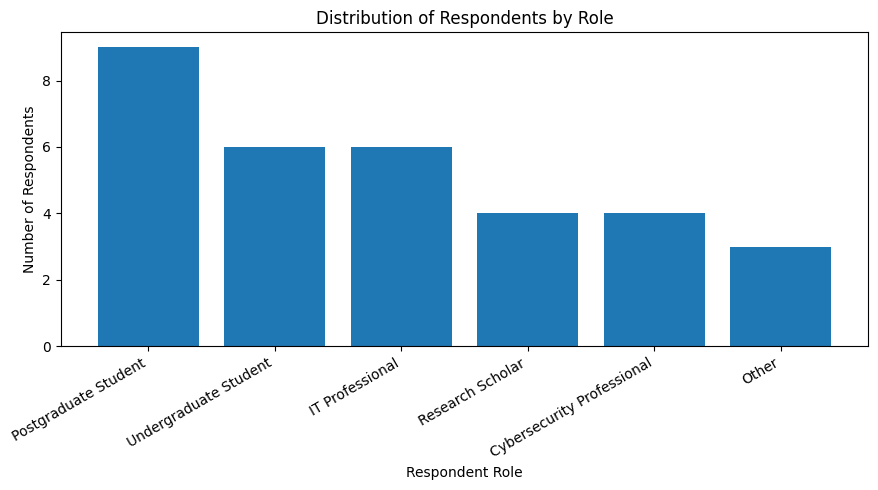

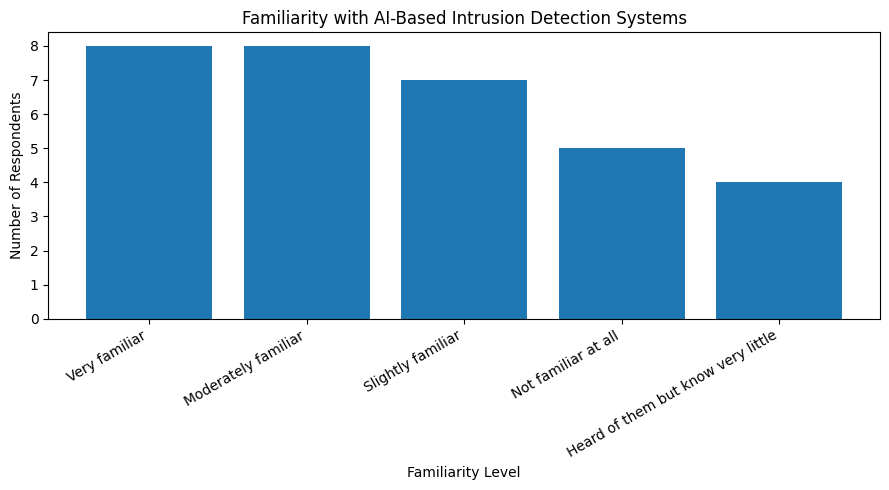

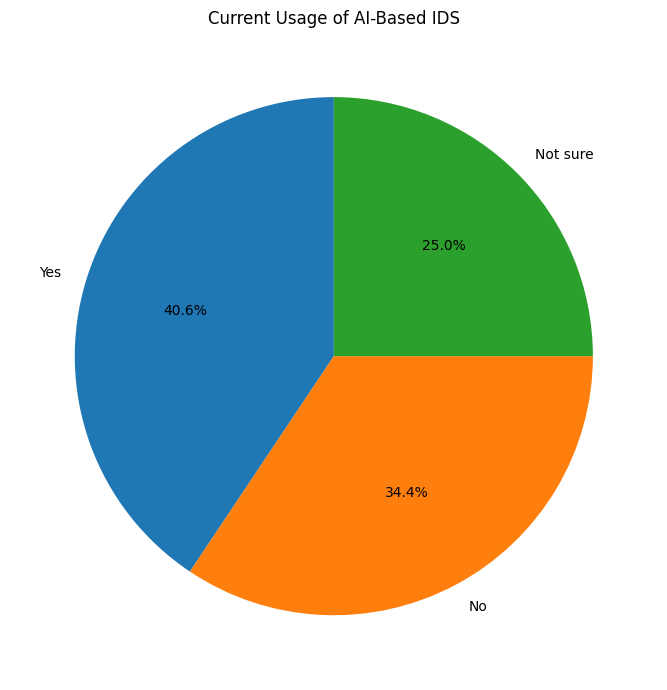

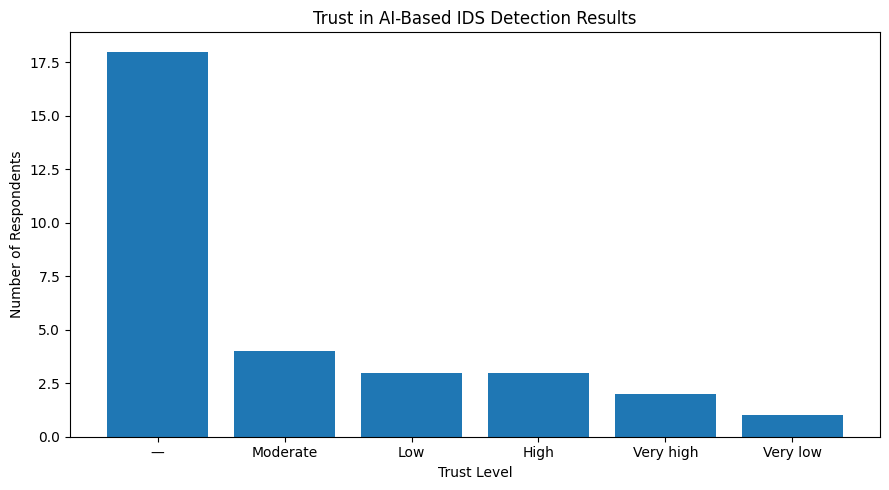

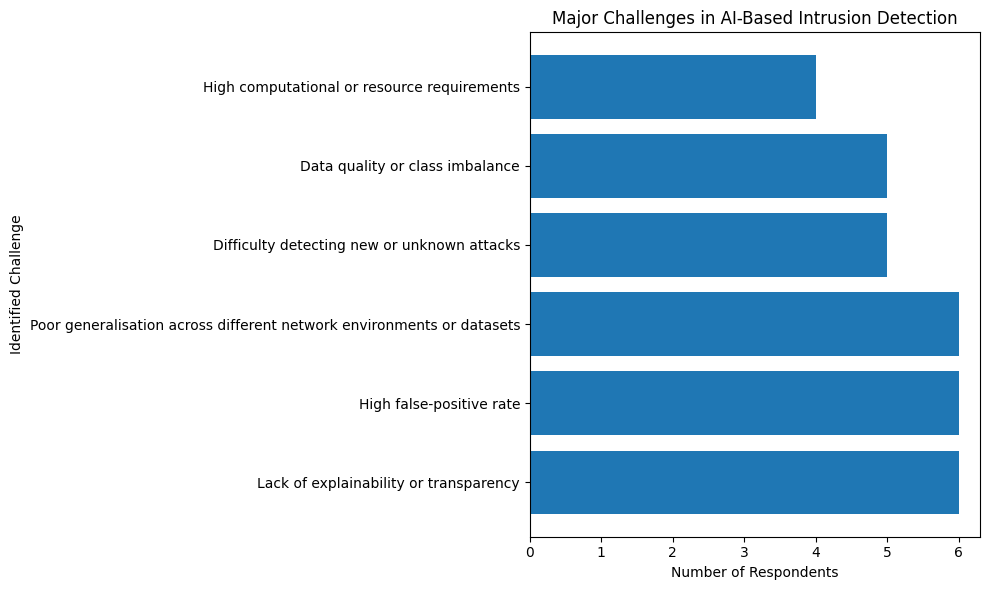

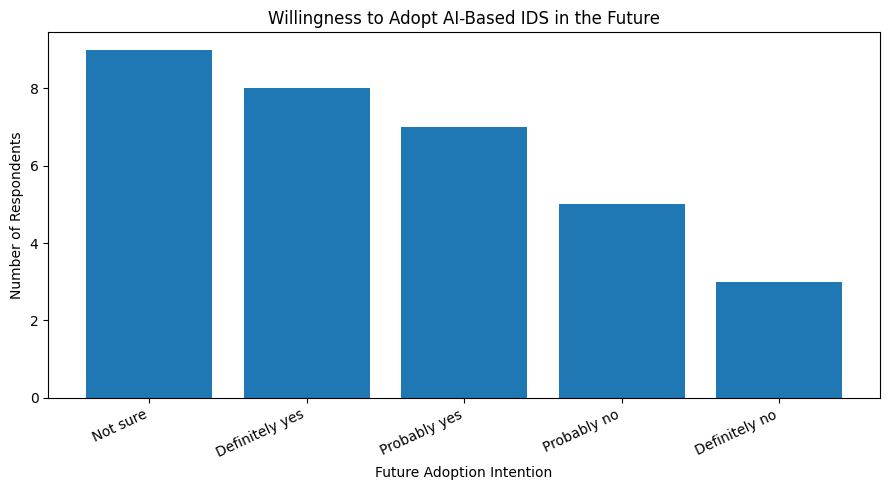

All six visualisations generated and saved successfully.


In [ ]:

# ==========================================
# VISUAL ANALYTICS USING MATPLOTLIB
# ==========================================

os.makedirs("Assignment6_Visualisations", exist_ok=True)

# Chart 1: Respondent role distribution
plt.figure(figsize=(9, 5))

role_counts = data["Role"].value_counts()

plt.bar(role_counts.index.astype(str), role_counts.values)
plt.title("Distribution of Respondents by Role")
plt.xlabel("Respondent Role")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/01_role_distribution.png")
plt.show()


# Chart 2: Familiarity with AI-based IDS
plt.figure(figsize=(9, 5))

familiarity_counts = data["Familiarity"].value_counts()

plt.bar(
    familiarity_counts.index.astype(str),
    familiarity_counts.values
)
plt.title("Familiarity with AI-Based Intrusion Detection Systems")
plt.xlabel("Familiarity Level")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/02_familiarity.png")
plt.show()


# Chart 3: Current usage of AI-based IDS
plt.figure(figsize=(7, 7))

usage_counts = data["Current_Use"].value_counts()

plt.pie(
    usage_counts.values,
    labels=usage_counts.index.astype(str),
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Current Usage of AI-Based IDS")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/03_current_usage.png")
plt.show()


# Chart 4: Trust in AI-based IDS
plt.figure(figsize=(9, 5))

trust_counts = data["Trust"].value_counts()

plt.bar(trust_counts.index.astype(str), trust_counts.values)
plt.title("Trust in AI-Based IDS Detection Results")
plt.xlabel("Trust Level")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/04_trust_levels.png")
plt.show()


# Chart 5: Biggest challenges
plt.figure(figsize=(10, 6))

challenge_counts = data["Biggest_Challenge"].value_counts()

plt.barh(
    challenge_counts.index.astype(str),
    challenge_counts.values
)
plt.title("Major Challenges in AI-Based Intrusion Detection")
plt.xlabel("Number of Respondents")
plt.ylabel("Identified Challenge")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/05_challenges.png")
plt.show()


# Chart 6: Future adoption
plt.figure(figsize=(9, 5))

adoption_counts = data["Future_Adoption"].value_counts()

plt.bar(
    adoption_counts.index.astype(str),
    adoption_counts.values
)
plt.title("Willingness to Adopt AI-Based IDS in the Future")
plt.xlabel("Future Adoption Intention")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("Assignment6_Visualisations/06_future_adoption.png")
plt.show()

print("All six visualisations generated and saved successfully.")


In [ ]:

# ==========================================
# SUMMARY OF KEY FINDINGS
# ==========================================

print("KEY FINDINGS FROM THE SURVEY")
print("====================================")

print("\nTotal valid survey records:", len(data))

for column in [
    "Role",
    "Familiarity",
    "Current_Use",
    "Trust",
    "Biggest_Challenge",
    "Future_Adoption"
]:
    counts = data[column].value_counts()

    if len(counts) > 0:
        print("\nMost common response for", column, ":")
        print(counts.index[0], "-", counts.iloc[0], "responses")

print("\nINTERPRETATION OF STATISTICAL TESTS")
print("====================================")

for result in [result1, result2]:
    if result is not None:
        print("\n", result["Analysis"])
        print("Test:", result["Test"])
        print("P-value:", round(result["P-value"], 4))

        if result["P-value"] < 0.05:
            print("Interpretation: Significant association found.")
        else:
            print("Interpretation: No significant association established.")


KEY FINDINGS FROM THE SURVEY

Total valid survey records: 32

Most common response for Role :
Postgraduate Student - 9 responses

Most common response for Familiarity :
Very familiar - 8 responses

Most common response for Current_Use :
Yes - 13 responses

Most common response for Trust :
— - 18 responses

Most common response for Biggest_Challenge :
Lack of explainability or transparency - 6 responses

Most common response for Future_Adoption :
Not sure - 9 responses

INTERPRETATION OF STATISTICAL TESTS

 Association between Familiarity and Current Usage
Test: Chi-square Test of Independence
P-value: 0.0719
Interpretation: No significant association established.

 Association between Current Usage and Future Adoption
Test: Chi-square Test of Independence
P-value: 0.9461
Interpretation: No significant association established.


In [ ]:

# ==========================================
# CREATE REPRODUCIBLE PROJECT STRUCTURE
# ==========================================

project = "Assignment6_Statistical_Analysis"

folders = [
    f"{project}/Dataset",
    f"{project}/Results",
    f"{project}/Visualisations"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Save anonymised dataset (timestamp excluded)
anonymous_data = data.drop(columns=["Timestamp"])

anonymous_data.to_excel(
    f"{project}/Dataset/Anonymized_Survey_Data.xlsx",
    index=False
)

# Save descriptive statistics
descriptive_results = []

for column in survey_questions:
    counts = data[column].value_counts(dropna=False)
    percentages = data[column].value_counts(
        normalize=True, dropna=False
    ) * 100

    for category, count in counts.items():
        descriptive_results.append({
            "Variable": column,
            "Response": str(category),
            "Frequency": count,
            "Percentage": round(percentages[category], 2)
        })

pd.DataFrame(descriptive_results).to_csv(
    f"{project}/Results/Descriptive_Statistics.csv",
    index=False
)

# Save inferential test results
test_results.to_csv(
    f"{project}/Results/Inferential_Statistics.csv",
    index=False
)

# Copy generated visualisations
shutil.copytree(
    "Assignment6_Visualisations",
    f"{project}/Visualisations",
    dirs_exist_ok=True
)

# Create README
readme = """# Assignment 6: Statistical Analysis and Visual Analytics

## Project Overview
This project performs descriptive and inferential statistical analysis
on survey responses concerning AI-based Network Intrusion Detection Systems.

## Objectives
- Clean and organise survey data.
- Perform descriptive statistical analysis.
- Examine associations using suitable inferential tests.
- Develop visual analytics using Matplotlib.
- Maintain a reproducible research workflow.

## Tools and Libraries
- Python
- Google Colab / Jupyter Notebook
- Pandas and NumPy
- SciPy
- Matplotlib
- OpenPyXL

## Project Structure
- Dataset: Anonymised survey dataset.
- Results: Descriptive and inferential statistical results.
- Visualisations: Generated charts and plots.
- Notebook: Complete executable analysis notebook.

## Reproducibility
1. Download or clone this repository.
2. Install the dependencies listed in requirements.txt.
3. Open the notebook in Jupyter Notebook or Google Colab.
4. Place the dataset in the Dataset folder.
5. Run the notebook cells in order.

## Statistical Methods
Frequency distributions, percentages, ordinal summaries,
Chi-square tests of independence, and Fisher's exact test
where appropriate.

## Data Privacy
The timestamp column has been excluded from the shared dataset.
The dataset should be shared only if permitted by the survey's
consent conditions and applicable privacy requirements.
"""

with open(f"{project}/README.md", "w", encoding="utf-8") as file:
    file.write(readme)

# Create requirements file
requirements = """pandas
numpy
matplotlib
scipy
openpyxl
jupyter
"""

with open(
    f"{project}/requirements.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(requirements)

# Zip the project folder
shutil.make_archive(project, "zip", project)

print("PROJECT CREATED SUCCESSFULLY!")
print("Project folder:", project)
print("ZIP file:", project + ".zip")


PROJECT CREATED SUCCESSFULLY!
Project folder: Assignment6_Statistical_Analysis
ZIP file: Assignment6_Statistical_Analysis.zip


In [ ]:

from google.colab import files

files.download("Assignment6_Statistical_Analysis.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>